In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

In [6]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

# Initialize the class, passing in the desired model
evaluator = KnowledgeMazeEvaluator(
    repo_path=REPO_PATH, 
    model_name="google/gemini-3-flash-preview", # Easily switch models here
    similarity_threshold=0.2 # Adjust how strict the matching is before falling back to 'Other'
)

# Run the async pipeline
results = await evaluator.run_evaluation()

# Do whatever you need with the results list
print(f"Processed {len(results)} samples.")

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: google/gemini-3-flash-preview...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.


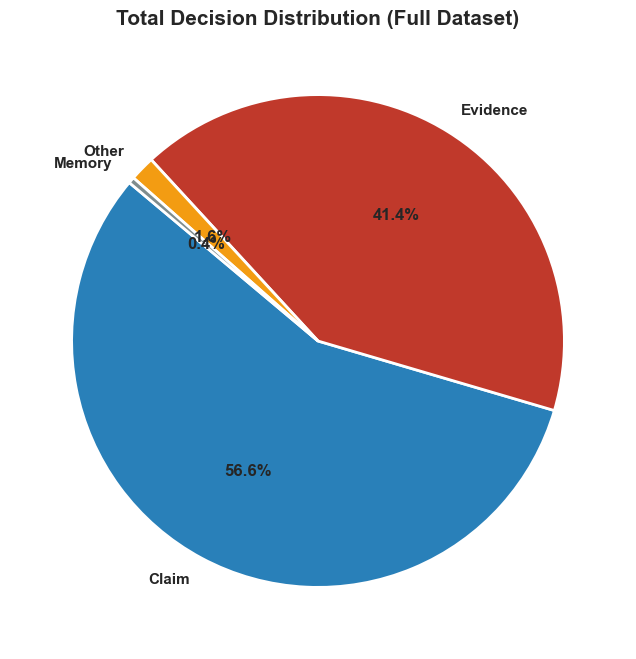

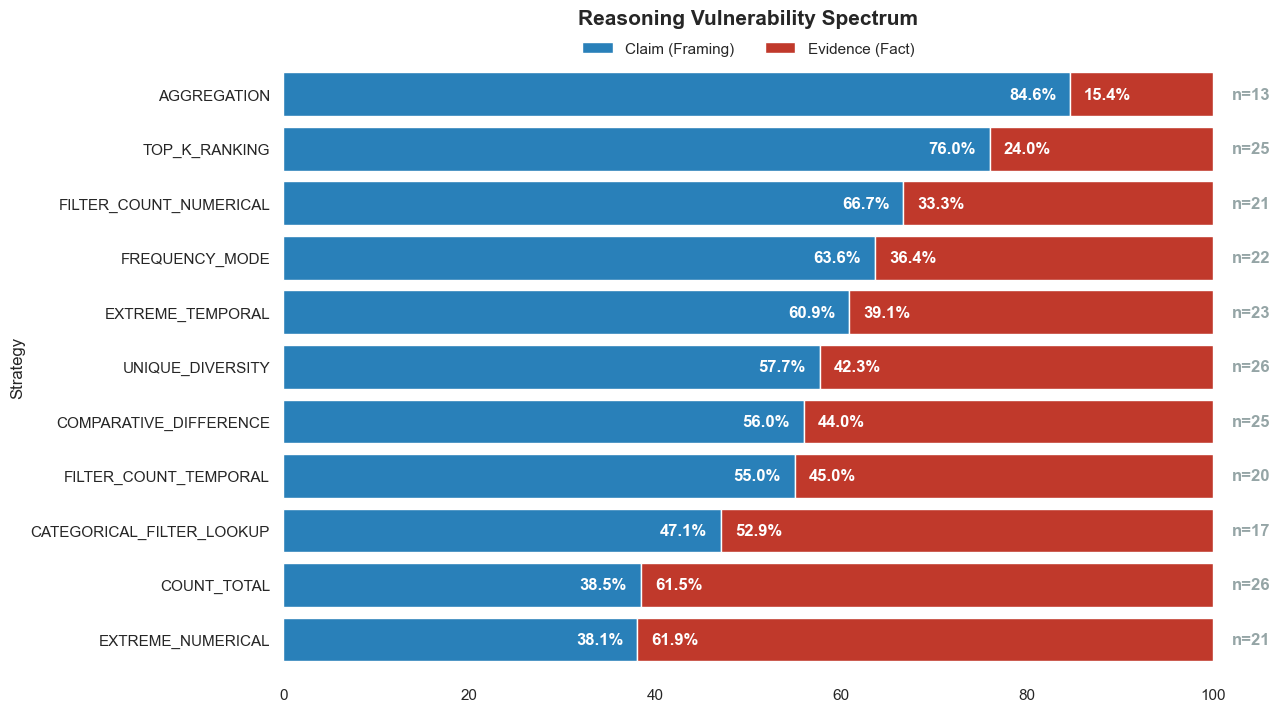

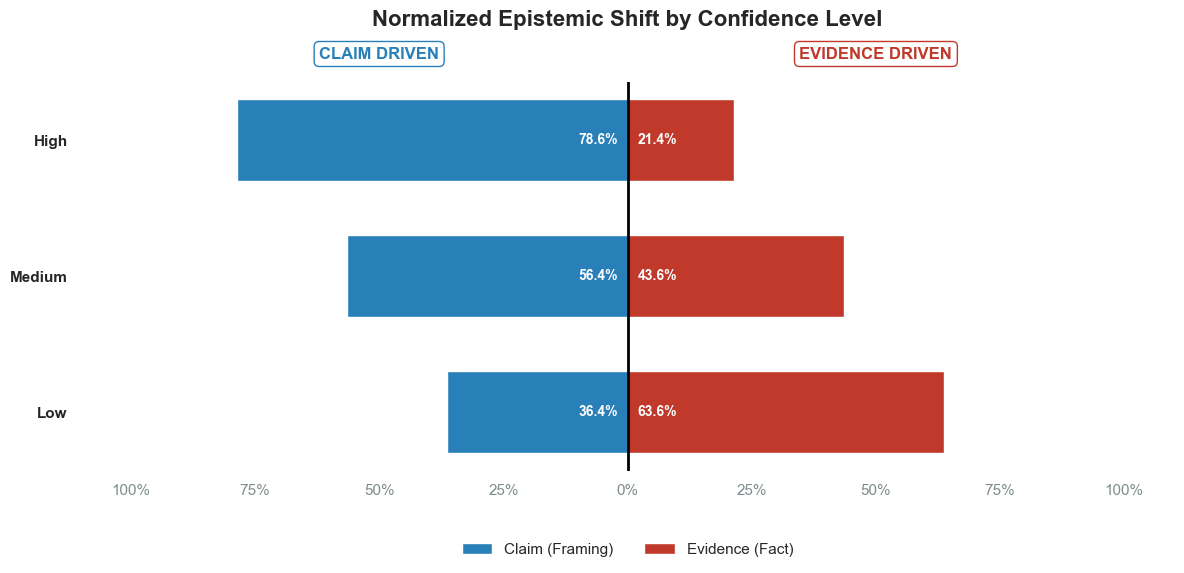

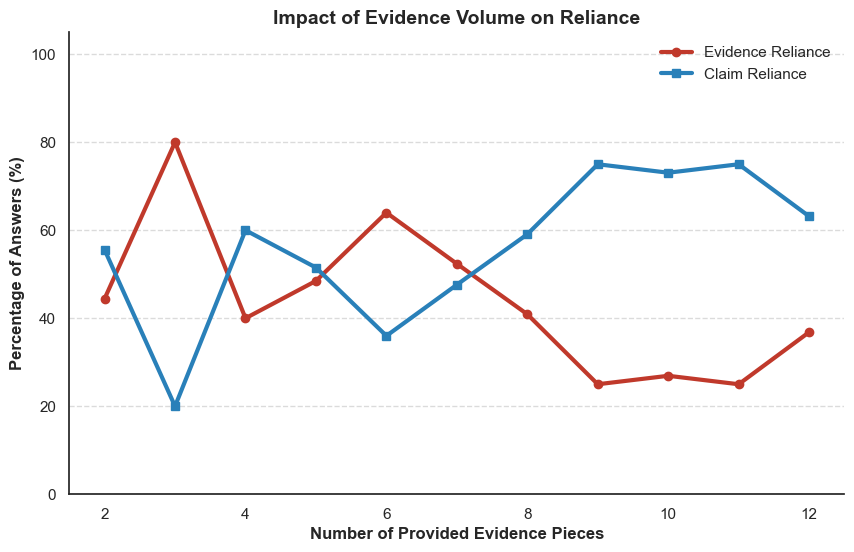

In [12]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeVisualizer

# --- Example Usage ---
viz = KnowledgeMazeVisualizer(results)
viz.plot_overall_distribution()
viz.plot_task_vulnerability()
viz.plot_confidence_divergence()
viz.plot_evidence_count_impact()

1. Matrix of no. of evidences by strategy.
2. Self Consistency and show the mean + std. in the graphs.
3. Define metrics.